In [9]:
from langchain_community.chat_models import ChatOpenAI
from typing_extensions import TypedDict, Literal
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Command, interrupt
from langchain_core.tools import tool
from langchain_core.messages import AIMessage
from IPython.display import Image, display
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os
load_dotenv()  # 必须要这句！
@tool
def weather_search(city: str):
    """搜索天气"""
    print("—————")
    print(f"正在搜索：{city}")
    print("—————")
    return f"{city}的天气现在非常晴朗！"

qwen = ChatOpenAI(
    model="qwen-plus",  # 或 qwen-max / qwen-turbo
    temperature=0,
    openai_api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1"
)
model = qwen.bind_tools([weather_search])



In [10]:
class State(MessagesState): #这里如果继承MessagesState 则自动增加一个Message，如果继承TypedDict 可以自主定制字段
    "简单状态"
def call_llm(state):
    return {"messages":[model.invoke(state["messages"])]}



In [11]:
def human_review_node(state) -> Command[Literal["call_llm", "run_tool"]]:
    last_message = state["messages"][-1]
    tool_call = last_message.tool_calls[-1]

    # 这是我们将通过 Command(resume=<human_review>) 提供的值
    human_review = interrupt(
        {
            "question": "这是正确的吗？",
            # 显示工具调用以供审核
            "tool_call": tool_call,
        }
    )
    print(human_review)
    review_action = human_review["action"]
    review_data = human_review.get("data")

    # 如果批准，调用工具
    if review_action == "continue":
        return Command(goto="run_tool")

    # 更新 AI 消息并调用工具 (此处代码未显示完全)
    elif review_action == "update":
        updated_message = {
            "role": "ai",
            "content": last_message.content,
            "tool_calls": [
                {
                    "id": tool_call["id"],
                    "name": tool_call["name"],
                    # 这是人类提供的更新，替换掉原本 LLM 生成的参数
                    "args": review_data,
                }
            ],
            # 这很重要 - 这需要与你替换的消息相同！
            # 否则，它将显示为一个单独的消息
            "id": last_message.id,
        }

        return Command(
            goto="run_tool",
            update={"messages": [updated_message]}
        )

    elif review_action == "feedback":


    # (带有工具调用的 AI 消息需要后跟工具调用消息)
        tool_message = {
            "role": "tool",
            # 这是我们的自然语言反馈
            "content": review_data,
            "name": tool_call["name"],
            "tool_call_id": tool_call["id"],
        }

    return Command(
        goto="call_llm",
        update={"messages": [tool_message]}
    )

In [12]:
def run_tool(state):
    new_messages = []
    # 注册可用工具映射
    tools = {"weather_search": weather_search}

    # 获取最后一条 AI 消息中的工具调用请求
    tool_calls = state["messages"][-1].tool_calls
    print(f"DEBUG: 准备执行工具，参数为: {state['messages'][-1].tool_calls[0]['args']}")
    for tool_call in tool_calls:
        # 根据名称找到对应的工具函数
        tool = tools[tool_call["name"]]
        # 传入 AI 生成的参数并执行
        print(f"真正传给工具函数的参数是: {tool_call['args']}")
        result = tool.invoke(tool_call["args"])

        # 构造符合协议的 ToolMessage
        new_messages.append(
            {
                "role": "tool",
                "name": tool_call["name"],
                "content": result,
                "tool_call_id": tool_call["id"],
            }
        )

    return {"messages": new_messages}

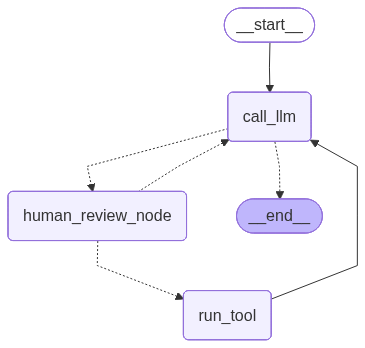

In [13]:
from typing import Literal # 如果你使用了 Literal，也需要导入它
def route_after_llm(state) -> Literal[END, "human_review_node"]:
    # 检查最后一条消息是否包含工具调用请求
    if len(state["messages"][-1].tool_calls) == 0:
        # 如果没有工具调用，直接结束流程
        return END
    else:
        # 如果有工具调用，进入人工审核节点
        return "human_review_node"

builder = StateGraph(State)
builder.add_node(call_llm)
builder.add_node(run_tool)
builder.add_node(human_review_node)

builder.add_edge(START, "call_llm")
# 添加条件边：根据 route_after_llm 的判断结果决定流向
builder.add_conditional_edges("call_llm", route_after_llm)
builder.add_edge("run_tool", "call_llm")

# 设置内存检查点，用于持久化状态
memory = MemorySaver()
graph = builder.compile(checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

In [14]:
initial_input = {"messages": [{"role": "user", "content": "深圳的天气如何"}]}

# 线程配置 (thread_id 决定了记忆的归属)
thread = {"configurable": {"thread_id": "2"}}
for event in graph.stream(initial_input,thread,stream_mode="updates"):
    print(event)
    print("\n")


{'call_llm': {'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 19, 'prompt_tokens': 146, 'total_tokens': 165, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'qwen-plus', 'system_fingerprint': None, 'id': 'chatcmpl-52dbdf76-b0a1-91b0-9636-4cac9ec72051', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019dc3e4-330e-7751-9dda-45650cef21c8-0', tool_calls=[{'name': 'weather_search', 'args': {'city': '深圳'}, 'id': 'call_30e27146a53345ec8afdc2', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 146, 'output_tokens': 19, 'total_tokens': 165, 'input_token_details': {'cache_read': 0}, 'output_token_details': {}})]}}


{'__interrupt__': (Interrupt(value={'question': '这是正确的吗？', 'tool_call': {'name': 'weather_search', 'args': {'city': '深圳'}, 'id': 'call_30e27146a53345ec8afdc2', 'typ

In [15]:
# for event in graph.stream(
#     Command(resume={"action": "continue"}),
#     thread,
#     stream_mode="updates"
# ):
#     print(event)

In [16]:
# 通过字典结构精准修正工具参数
for event in graph.stream(
    Command(resume={"action": "update", "data": {"city": "上海,中国"}}),
    thread,
    stream_mode="updates",
):
    print(event)
    print("\n")

"""你执行了 Command(resume=...)：你的代码成功地将原本查“深圳”的意图，通过 id 替换，改成了查“上海”。

run_tool 执行：结果返回了 上海的天气现在非常晴朗！。

call_llm 节点被激活：此时模型拿到了更新后的消息列表，它的上下文变成了：

    用户之前可能提过深圳。

    当前最后一条记录：它自己（AI）问了上海，工具也回了上海。

模型的大脑“抽筋”了：

    AI 内容：深圳的天气如何？我刚才搜索的是上海的天气，让我为您查询深圳的天气。

模型逻辑是： “咦？我刚才怎么查了上海？用户明明最开始想要的是深圳啊（受之前的 HumanMessage 影响）。既然上海查完了，那为了‘完成任务’，我得把深圳补上。”

方案 B：在 Feedback 里加入指令（推荐）

如果你不希望它查深圳，你应该使用你的 "feedback" 逻辑，而不是单纯的 "update"。

    告诉它："忽略深圳，只查询上海，查完上海后直接回答。"
"""

{'action': 'update', 'data': {'city': '上海,中国'}}
{'human_review_node': {'messages': [{'role': 'ai', 'content': '', 'tool_calls': [{'id': 'call_30e27146a53345ec8afdc2', 'name': 'weather_search', 'args': {'city': '上海,中国'}}], 'id': 'lc_run--019dc3e4-330e-7751-9dda-45650cef21c8-0'}]}}


DEBUG: 准备执行工具，参数为: {'city': '上海,中国'}
真正传给工具函数的参数是: {'city': '上海,中国'}
—————
正在搜索：上海,中国
—————
{'run_tool': {'messages': [{'role': 'tool', 'name': 'weather_search', 'content': '上海,中国的天气现在非常晴朗！', 'tool_call_id': 'call_30e27146a53345ec8afdc2'}]}}


{'call_llm': {'messages': [AIMessage(content='深圳的天气如何？我刚才搜索的是上海的天气，让我为您查询深圳的天气。\n\n', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 190, 'total_tokens': 229, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 64}}, 'model_provider': 'openai', 'model_name': 'qwen-plus', 'system_fingerprint': None, 'id': 'chatcmpl-5243ac42-8a73-993d-a20f-9ad2f9807320', 'fi

'你执行了 Command(resume=...)：你的代码成功地将原本查“深圳”的意图，通过 id 替换，改成了查“上海”。\n\nrun_tool 执行：结果返回了 上海的天气现在非常晴朗！。\n\ncall_llm 节点被激活：此时模型拿到了更新后的消息列表，它的上下文变成了：\n\n    用户之前可能提过深圳。\n\n    当前最后一条记录：它自己（AI）问了上海，工具也回了上海。\n\n模型的大脑“抽筋”了：\n\n    AI 内容：深圳的天气如何？我刚才搜索的是上海的天气，让我为您查询深圳的天气。\n\n模型逻辑是： “咦？我刚才怎么查了上海？用户明明最开始想要的是深圳啊（受之前的 HumanMessage 影响）。既然上海查完了，那为了‘完成任务’，我得把深圳补上。”\n\n方案 B：在 Feedback 里加入指令（推荐）\n\n如果你不希望它查深圳，你应该使用你的 "feedback" 逻辑，而不是单纯的 "update"。\n\n    告诉它："忽略深圳，只查询上海，查完上海后直接回答。"\n'